# 03 – Analyse : décès accidentels liés aux drogues (Connecticut, 2012-2022)

Ce notebook part du fichier nettoyé `data/processed/deces_nettoyes.csv` produit par `02_nettoyage.ipynb`.
Il répond aux questions métier par des agrégations et des visualisations.

**Questions étudiées :**
1. Parmi les 5 substances les plus souvent détectées, quelle part des décès implique chacune, et comment cette part a-t-elle évolué de 2012 à 2022 ?
2. Quelles associations de substances reviennent le plus souvent parmi les décès ?
3. Quel est le profil (âge, sexe) des personnes décédées, et a-t-il changé entre 2012 et 2022 ?
4. Quels comtés comptent le plus de décès, en nombre et rapporté à leur population ?
5. Les décès surviennent-ils majoritairement au domicile ou à l'hôpital ?

Rappel : on compte des **détections** de substances, pas des causes. Un décès peut impliquer plusieurs substances.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

deces = pd.read_csv("../data/processed/deces_nettoyes.csv", parse_dates=["Date"])
print(deces.shape)

(10653, 46)


In [2]:
colonnes_substances = deces.loc[:, "Heroin":"Any Opioid"].columns
print(deces["Date"].dtype)
print(deces[colonnes_substances].dtypes.value_counts())

datetime64[us]
bool    21
Name: count, dtype: int64


## Q1 – Quelles substances sont le plus souvent détectées, et comment leur part a-t-elle évolué ?

Pour classer les substances, on exclut 4 colonnes qui ne désignent pas une substance précise mais un **regroupement** ou une **mention administrative** :
`Any Opioid` (tout opioïde confondu), `Heroin/Morph/Codeine` et `Opiate NOS` (catégories regroupées ou non précisées), `Heroin death certificate (DC)` (mention sur le certificat de décès, qui doublonne `Heroin`).
Les garder ferait monter artificiellement des catégories qui recoupent les autres. On classe donc les 17 substances restantes.

In [3]:
colonnes_exclues = ["Any Opioid", "Heroin/Morph/Codeine", "Opiate NOS", "Heroin death certificate (DC)"]
substances_individuelles = deces[colonnes_substances].drop(columns=colonnes_exclues)
detections_par_substance = substances_individuelles.sum()
detections_par_substance = detections_par_substance.sort_values(ascending=False)
print(detections_par_substance)

Fentanyl                 6925
Cocaine                  3855
Heroin                   3472
Ethanol                  2877
Benzodiazepine           2499
Oxycodone                 949
Methadone                 938
Fentanyl Analogue         804
Xylazine                  792
Amphet                    359
Gabapentin                348
Tramad                    284
Hydrocodone               163
Oxymorphone               157
Meth/Amphetamine          127
Hydromorphone              67
Morphine (Not Heroin)      52
dtype: int64


In [4]:
top5_substances = list(detections_par_substance.index[:5])
part_deces_top5 = deces[top5_substances].mean()
part_deces_top5 = part_deces_top5.sort_values(ascending=False)
print(top5_substances)
print(part_deces_top5)

['Fentanyl', 'Cocaine', 'Heroin', 'Ethanol', 'Benzodiazepine']
Fentanyl          0.650052
Cocaine           0.361870
Heroin            0.325918
Ethanol           0.270065
Benzodiazepine    0.234582
dtype: float64


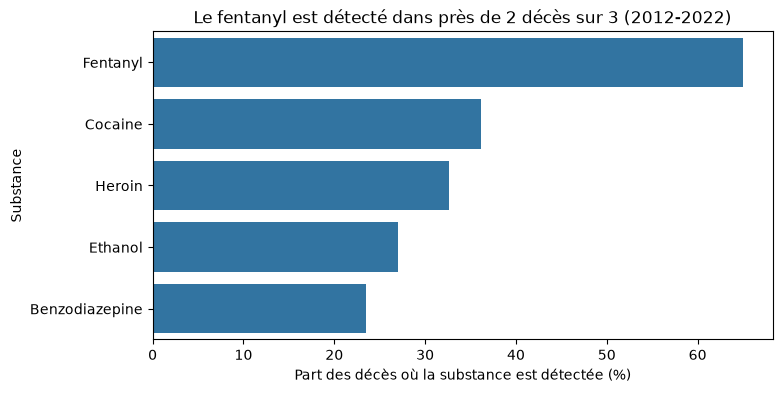

In [5]:
pourcentage_top5 = part_deces_top5 * 100

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=pourcentage_top5.values, y=pourcentage_top5.index, ax=ax)
ax.set_title("Le fentanyl est détecté dans près de 2 décès sur 3 (2012-2022)")
ax.set_xlabel("Part des décès où la substance est détectée (%)")
ax.set_ylabel("Substance")
fig.savefig("../figures/01_top5_substances.png")
plt.show()

**Conclusion :** sur l'ensemble de la période 2012-2022, le fentanyl est détecté dans 65,0 % des décès, soit près de 2 sur 3. C'est près de deux fois plus que la cocaïne (36,2 %) et l'héroïne (32,6 %), qui suivent à un niveau proche. L'alcool (27,0 %) et les benzodiazépines (23,5 %) complètent le top 5. Ces parts portent sur toute la période : la suite vérifie si cette domination du fentanyl a toujours existé ou si elle est récente.

In [6]:
deces["Annee"] = deces["Date"].dt.year
part_par_annee = deces.groupby("Annee")[top5_substances].mean() * 100
print(part_par_annee.round(1))

       Fentanyl  Cocaine  Heroin  Ethanol  Benzodiazepine
Annee                                                    
2012        4.0     29.7    49.2     17.2            13.8
2013        7.6     30.0    52.4     16.9            15.9
2014       13.4     22.8    58.2     22.6            28.1
2015       25.9     24.3    57.2     24.1            30.3
2016       52.6     30.0    53.9     27.8            26.4
2017       65.1     33.4    45.7     27.9            31.8
2018       74.7     33.9    38.4     25.1            26.3
2019       81.6     38.6    32.2     28.5            24.2
2020       84.4     38.5    19.1     29.4            22.3
2021       85.4     43.0    10.9     31.3            19.5
2022       86.3     47.1     8.6     28.1            18.0


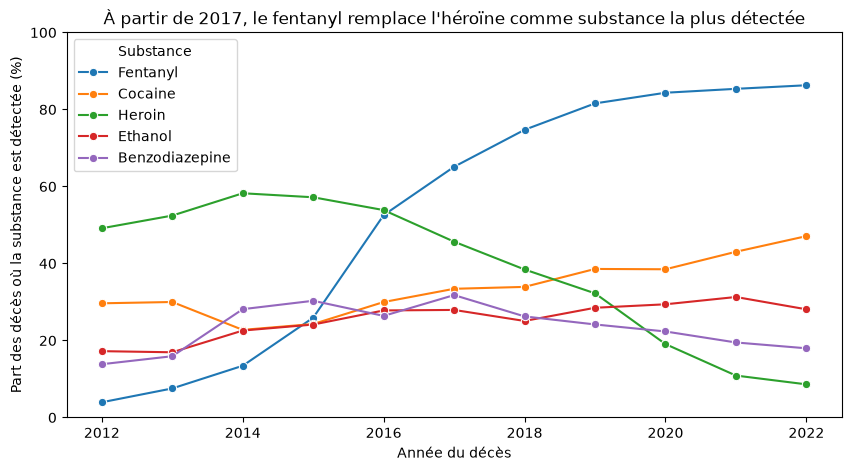

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=part_par_annee, dashes=False, marker="o", ax=ax)
ax.set_title("À partir de 2017, le fentanyl remplace l'héroïne comme substance la plus détectée")
ax.set_xlabel("Année du décès")
ax.set_ylabel("Part des décès où la substance est détectée (%)")
ax.set_ylim(0, 100)
ax.legend(title="Substance")
fig.savefig("../figures/02_evolution_top5.png")
plt.show()

**Conclusion :** le profil des substances détectées s'est profondément transformé en 11 ans.
- Le **fentanyl** passe de 4,0 % des décès en 2012 à 86,3 % en 2022.
- L'**héroïne** atteint son maximum en 2014 (58,2 %), puis recule nettement à partir de 2016-2017 jusqu'à 8,6 % en 2022.
- Les deux courbes se croisent en **2017** : le fentanyl est alors détecté dans 65,1 % des décès, contre 45,7 % pour l'héroïne (en 2016, les deux étaient encore au coude-à-coude : 52,6 % contre 53,9 %).
- La **cocaïne** progresse aussi, de 29,7 % à 47,1 %, après un creux en 2014 (22,8 %).

Ces données montrent un **remplacement** de l'héroïne par le fentanyl parmi les substances détectées. Elles ne disent pas pourquoi : le jeu de données ne contient que des décès, il ne permet pas de mesurer la consommation.

## Q2 : Quelles associations de substances reviennent le plus souvent parmi les décès ?

La Q1 a montré que le top 5 totalise 19 628 détections pour 10 653 décès :
plusieurs substances sont donc souvent détectées lors d'un même décès.
On cherche ici quelles substances apparaissent **ensemble**.

**Périmètre** : on se limite aux 5 substances les plus détectées (`top5_substances`),
pour garder un tableau lisible (5 × 5) et des effectifs suffisants.

**Mesure** : pour chaque paire (A, B), on calcule la part des décès où B est aussi
détectée **parmi les décès où A est détectée** (filtre booléen puis `mean`).
Cette mesure n'est pas symétrique : « parmi les décès avec A, part avec B »
n'est pas égale à « parmi les décès avec B, part avec A ».

**Précaution** : on mesure des **co-détections**, pas des interactions ni des causes.
Une association fréquente indique que deux substances sont souvent présentes
ensemble, pas que leur combinaison explique le décès.

In [8]:
deces_avec_fentanyl = deces[deces["Fentanyl"]]
part_cocaine = deces_avec_fentanyl["Cocaine"].mean()

print(f"Décès avec fentanyl détecté : {len(deces_avec_fentanyl)}")
print(f"Parmi eux, part avec cocaïne : {part_cocaine * 100:.1f} %")

Décès avec fentanyl détecté : 6925
Parmi eux, part avec cocaïne : 39.0 %


**Contrôle sur une paire : fentanyl et cocaïne.**
Parmi les 6 925 décès où le fentanyl est détecté (effectif identique à la Q1, le filtre est correct),
la cocaïne est aussi détectée dans **39,0 %** des cas, contre 36,2 % sur l'ensemble des décès.
L'écart est faible (+2,8 points) : la cocaïne n'est pas beaucoup plus fréquente en présence de fentanyl.
Hypothèse non vérifiée : les deux substances progressent sur la même période (Q1),
ce qui peut suffire à expliquer une partie de cet écart.

On généralise maintenant ce calcul à toutes les paires du top 5.

In [9]:
parts_associations = {}

for substance_reference in top5_substances:
    deces_avec_reference = deces[deces[substance_reference]]
    parts_associations[substance_reference] = deces_avec_reference[top5_substances].mean() * 100

tableau_associations = pd.DataFrame(parts_associations)
tableau_associations.round(1)

,Fentanyl,Cocaine,Heroin,Ethanol,Benzodiazepine
Fentanyl,100.0,70.1,55.2,65.9,57.2
Cocaine,39.0,100.0,31.6,34.0,24.0
Heroin,27.7,28.5,100.0,30.1,31.8
Ethanol,27.4,25.4,24.9,100.0,24.6
Benzodiazepine,20.6,15.5,22.9,21.4,100.0


**Lecture du tableau des associations** (colonne = substance de référence, ligne = substance aussi détectée).
Exemple : colonne `Cocaine`, ligne `Fentanyl` = 70,1 → parmi les décès où la cocaïne est détectée,
70,1 % comportent aussi du fentanyl.

Les valeurs brutes reflètent surtout la fréquence globale de chaque substance :
la ligne `Fentanyl` est élevée partout car le fentanyl est détecté dans 65,0 % de l'ensemble des décès,
la ligne `Benzodiazepine` est basse partout car ce taux n'est que de 23,5 %.
Pour repérer de vraies associations, on compare chaque case à la part globale de la substance en ligne :
**écart = part parmi les décès avec la substance de référence − part sur l'ensemble des décès** (en points).
Un écart positif signifie que les deux substances sont détectées ensemble plus souvent que la moyenne,
un écart négatif moins souvent.

In [10]:
part_globale = deces[top5_substances].mean() * 100

ecarts_associations = {}
for substance_reference in top5_substances:
    deces_avec_reference = deces[deces[substance_reference]]
    part_avec_reference = deces_avec_reference[top5_substances].mean() * 100
    ecarts_associations[substance_reference] = part_avec_reference - part_globale

tableau_ecarts = pd.DataFrame(ecarts_associations)
tableau_ecarts.round(1)

,Fentanyl,Cocaine,Heroin,Ethanol,Benzodiazepine
Fentanyl,35.0,5.1,-9.8,0.9,-7.8
Cocaine,2.8,63.8,-4.6,-2.2,-12.2
Heroin,-4.9,-4.1,67.4,-2.5,-0.8
Ethanol,0.4,-1.6,-2.1,73.0,-2.4
Benzodiazepine,-2.8,-7.9,-0.6,-2.0,76.5


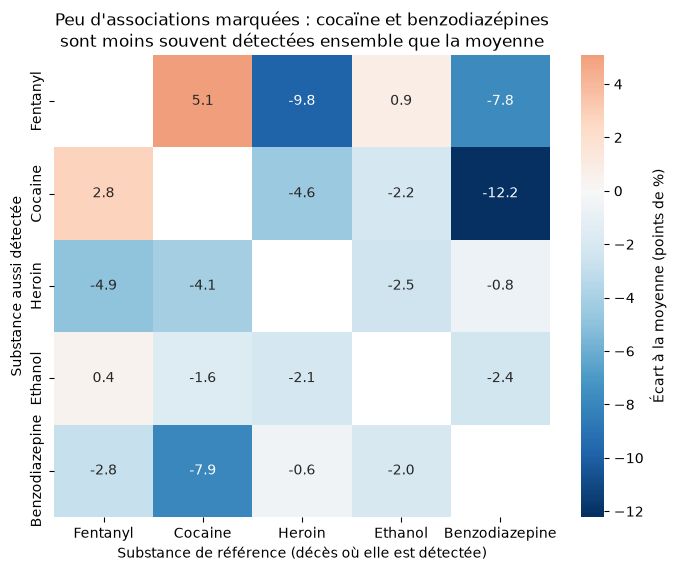

In [11]:
for substance in top5_substances:
    tableau_ecarts.loc[substance, substance] = None

figure, axe = plt.subplots(figsize=(8, 6))
sns.heatmap(tableau_ecarts, annot=True, fmt=".1f", cmap="RdBu_r", center=0,
            cbar_kws={"label": "Écart à la moyenne (points de %)"}, ax=axe)
axe.set_title("Peu d'associations marquées : cocaïne et benzodiazépines\nsont moins souvent détectées ensemble que la moyenne")
axe.set_xlabel("Substance de référence (décès où elle est détectée)")
axe.set_ylabel("Substance aussi détectée")
figure.savefig("../figures/03_associations_top5.png", bbox_inches="tight")
plt.show()

**Conclusion Q2.** La plupart des écarts sont compris entre −5 et +5 points : les substances du top 5
sont généralement détectées ensemble à une fréquence proche de leur fréquence moyenne.
Les écarts nets sont surtout négatifs :
- **cocaïne et benzodiazépines** : parmi les décès où les benzodiazépines sont détectées, la cocaïne l'est
  12,2 points de moins que sur l'ensemble des décès ;
- **fentanyl et héroïne** (−9,8 / −4,9) : cohérent avec la Q1, où le fentanyl remplace l'héroïne à partir de 2017.
  Hypothèse : les deux substances dominent des périodes différentes plutôt qu'elles ne s'excluent ;
- **fentanyl et benzodiazépines** (−7,8).

La seule association positive notable est **fentanyl et cocaïne** (+5,1 / +2,8).

**Limites** : on mesure des co-détections, pas des causes ; les écarts ne tiennent pas compte de l'année,
donc une partie peut venir de l'évolution des substances dans le temps ; analyse limitée au top 5.

## Q3 : Profil des personnes décédées (âge, sexe) et évolution 2012-2022

**Objectif** : décrire l'âge et le sexe des personnes décédées, puis vérifier si ce profil a changé entre 2012 et 2022.

**Méthode**
1. Âge : distribution globale (statistiques descriptives, histogramme), puis tranches d'âge avec `pd.cut` pour comparer les années.
2. Sexe : part de chaque sexe parmi les décès, sur toute la période puis année par année.
3. Évolution : on compare des **proportions** par année, car le nombre total de décès varie fortement d'une année à l'autre.

**Précautions**
- 9 décès de sexe `Unknown` : comptés dans le total, mais non affichés dans les graphiques par sexe.
- 2 âges manquants ont été remplacés par la médiane (43 ans) au nettoyage : effet négligeable sur 10 653 décès.
- Le jeu ne contient que des décès : on décrit la répartition **parmi les décès**, pas un risque par âge ou par sexe (il faudrait connaître la population de chaque groupe).

In [12]:
# Q3 : vue d'ensemble de l'âge et du sexe
print(deces["Age"].dtype)
print(deces["Age"].describe())
print(deces["Sex"].value_counts(normalize=True) * 100)

int64
count    10653.000000
mean        43.513470
std         12.599969
min         13.000000
25%         33.000000
50%         43.000000
75%         54.000000
max         87.000000
Name: Age, dtype: float64
Sex
Male       74.054257
Female     25.861260
Unknown     0.084483
Name: proportion, dtype: float64


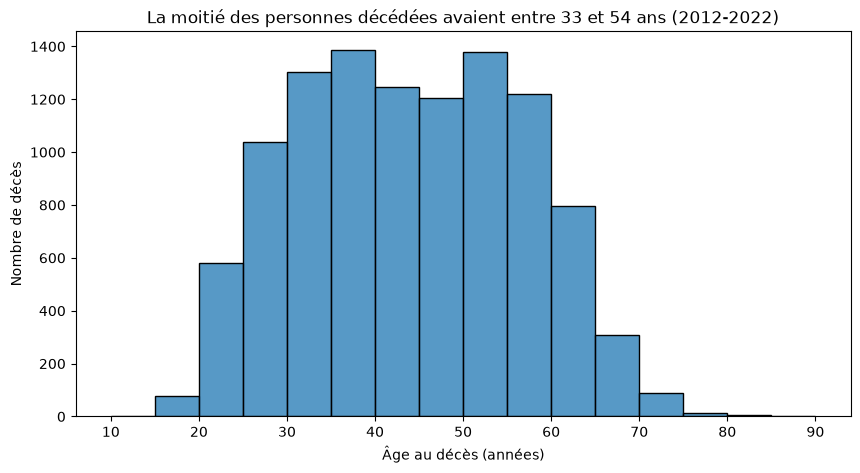

In [13]:
# Graphique 4 : distribution de l'âge au décès
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=deces, x="Age", binwidth=5, binrange=(10, 90), ax=ax)
ax.set_title("La moitié des personnes décédées avaient entre 33 et 54 ans (2012-2022)")
ax.set_xlabel("Âge au décès (années)")
ax.set_ylabel("Nombre de décès")
fig.savefig("../figures/04_distribution_age.png", bbox_inches="tight")
plt.show()

In [14]:
# Contrôle du graphique 4 : nombre de décès par tranche de 5 ans
tranches_5_ans = pd.cut(deces["Age"], bins=range(10, 95, 5), right=False)
print(tranches_5_ans.value_counts().sort_index())

Age
[10, 15)       3
[15, 20)      76
[20, 25)     579
[25, 30)    1039
[30, 35)    1302
[35, 40)    1387
[40, 45)    1248
[45, 50)    1206
[50, 55)    1380
[55, 60)    1220
[60, 65)     798
[65, 70)     309
[70, 75)      88
[75, 80)      13
[80, 85)       4
[85, 90)       1
Name: count, dtype: int64


**Conclusion graphique 4 :** les décès concernent surtout des adultes d'âge moyen.
- 72,7 % des décès touchent des personnes de 30 à 59 ans (7 743 sur 10 653).
- La distribution présente **deux pics presque égaux** : 35-39 ans (1 387 décès) et 50-54 ans (1 380), séparés par un léger creux à 45-49 ans (1 206).
- Les décès sont rares aux extrêmes : 79 avant 20 ans (0,7 %), 415 à partir de 65 ans (3,9 %).

Cette distribution regroupe 11 années. Le double pic pourrait venir d'un profil d'âge qui change avec le temps : la suite vérifie si la répartition par âge a évolué entre 2012 et 2022.

**Évolution de l'âge au décès entre 2012 et 2022**

On calcule, pour chaque année, le nombre de décès, l'âge médian et l'âge moyen. La médiane est l'indicateur principal, car elle est peu sensible aux âges extrêmes. Si elle bouge, on regardera ensuite quelles tranches d'âge expliquent ce changement.

In [15]:
# Q3 : âge au décès, année par année
age_par_annee = deces.groupby("Annee").agg(
    nombre_deces=("Age", "count"),
    age_median=("Age", "median"),
    age_moyen=("Age", "mean"),
)
print(age_par_annee.round(1))

       nombre_deces  age_median  age_moyen
Annee                                     
2012            354        41.0       40.7
2013            490        43.0       41.4
2014            558        42.5       41.6
2015            729        43.0       42.3
2016            917        42.0       42.1
2017           1038        40.0       41.7
2018           1017        42.0       42.8
2019           1200        42.0       43.3
2020           1374        43.0       43.7
2021           1524        46.0       45.8
2022           1452        47.0       46.6


In [16]:
# Q3 : part de chaque tranche d'âge, année par année
bornes_ages = [0, 25, 35, 45, 55, 65, 100]
noms_tranches = ["Moins de 25 ans", "25-34 ans", "35-44 ans", "45-54 ans", "55-64 ans", "65 ans et plus"]
deces["Tranche_age"] = pd.cut(deces["Age"], bins=bornes_ages, labels=noms_tranches, right=False)
part_tranches_par_annee = pd.crosstab(deces["Annee"], deces["Tranche_age"], normalize="index") * 100
print(part_tranches_par_annee.round(1))

Tranche_age  Moins de 25 ans  25-34 ans  35-44 ans  45-54 ans  55-64 ans  \
Annee                                                                      
2012                    11.3       24.3       20.3       30.8       10.7   
2013                     9.8       24.3       21.6       28.0       15.1   
2014                     7.5       23.1       27.2       29.2       10.0   
2015                     8.5       23.6       21.3       25.8       18.0   
2016                     6.9       25.4       23.3       26.0       16.4   
2017                     7.8       26.1       24.5       22.9       17.0   
2018                     7.0       22.7       25.9       24.8       16.2   
2019                     5.2       23.3       26.7       21.6       19.4   
2020                     5.9       22.3       25.5       21.7       20.2   
2021                     4.1       16.9       25.0       24.9       24.3   
2022                     3.0       17.7       25.3       22.4       23.9   

Tranche_age

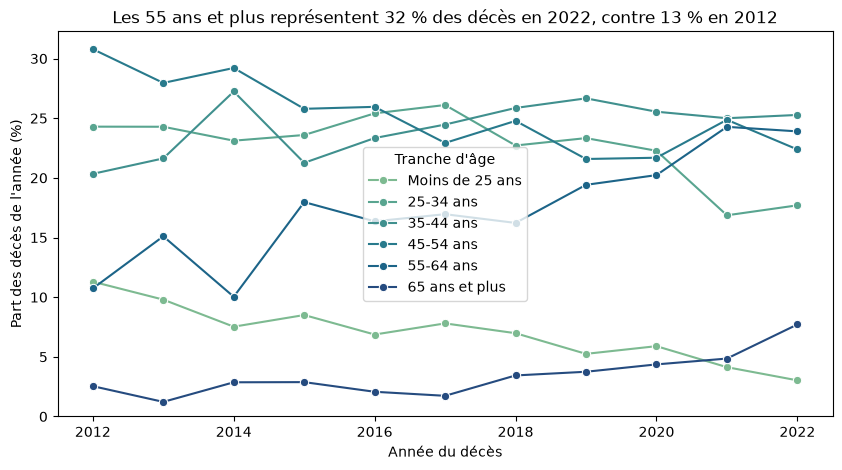

In [17]:
# Graphique 5 : évolution de la part de chaque tranche d'âge
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=part_tranches_par_annee, dashes=False, marker="o", palette="crest", ax=ax)
ax.set_title("Les 55 ans et plus représentent 32 % des décès en 2022, contre 13 % en 2012")
ax.set_xlabel("Année du décès")
ax.set_ylabel("Part des décès de l'année (%)")
ax.set_ylim(bottom=0)
ax.legend(title="Tranche d'âge")
fig.savefig("../figures/05_evolution_tranches_age.png", bbox_inches="tight")
plt.show()

**Conclusion graphique 5 :** le profil d'âge des personnes décédées a vieilli entre 2012 et 2022.
- Les **55 ans et plus** passent de 13,2 % à 31,6 % des décès (55-64 ans : 10,7 % → 23,9 % ; 65 ans et plus : 2,5 % → 7,7 %).
- Les **moins de 25 ans** reculent régulièrement, de 11,3 % à 3,0 %.
- Les **25-34 ans** restent stables autour de 23-26 % jusqu'en 2020, puis tombent à 17 % en 2021-2022. C'est ce qui explique le saut de l'âge médian ces deux années (42-43 ans jusqu'en 2020, puis 46 et 47 ans).
- Les 35-44 ans restent stables autour de 25 %.

Ces parts décrivent la composition des décès de chaque année, pas un risque par âge : une tranche peut prendre plus de place parce que ses décès augmentent, ou parce que ceux des autres tranches augmentent moins vite.

In [18]:
# Q3 : part des femmes et des hommes parmi les décès, année par année
part_sexe_par_annee = pd.crosstab(deces["Annee"], deces["Sex"], normalize="index") * 100
print(part_sexe_par_annee[["Female", "Male"]].round(1))

Sex    Female  Male
Annee              
2012     27.4  72.6
2013     28.6  71.4
2014     29.9  69.9
2015     26.2  73.8
2016     25.3  74.7
2017     25.0  74.9
2018     23.6  76.4
2019     24.0  75.9
2020     25.0  74.7
2021     26.9  73.0
2022     26.7  73.3


**Sexe :** les hommes représentent environ 3 décès sur 4 sur toute la période (74,1 % contre 25,9 % de femmes). Cette répartition est **stable** : la part des femmes varie entre 23,6 % (2018) et 29,9 % (2014), sans tendance nette entre 2012 et 2022. Pas de graphique ici, une courbe quasi plate n'apporterait rien de plus que ces chiffres.

## Conclusion Q3

- **Âge** : les décès concernent surtout des adultes de 30 à 59 ans (72,7 %). Le profil a **vieilli** : la part des 55 ans et plus passe de 13,2 % à 31,6 %, et l'âge médian monte de 41 à 47 ans, avec un saut en 2021-2022.
- **Sexe** : environ 3 décès sur 4 concernent des hommes, une proportion stable sur toute la période.

**Limites** : ces résultats décrivent la composition des décès, pas un risque par âge ou par sexe (il faudrait la population de chaque groupe). Les 9 décès de sexe inconnu ne sont pas affichés.

## Q4 : Quels comtés comptent le plus de décès, en nombre et rapporté à leur population ?

**Objectif** : comparer les 8 comtés du Connecticut, d'abord en nombre de décès (2012-2022), puis en décès pour 100 000 habitants.

**Méthode**
1. Identifier le comté de **résidence** de chaque personne décédée (colonne `Residence County`), en ne gardant que les résidents du Connecticut.
2. Construire une petite table comté → population (recensement 2020), saisie à la main depuis une source citée dans le README.
3. Joindre les deux tables avec `merge` (étape 06), contrôler le nombre de lignes, puis calculer un taux pour 100 000 habitants.

**Pourquoi un taux ?** Les comtés n'ont pas la même taille : un grand comté aura mécaniquement plus de décès. Le taux permet de comparer à population égale.

**Précaution** : le filtre sur les comtés est propre à la Q4. Il n'enlève aucune ligne du tableau `deces`.

In [19]:
comtes_residence = deces["Residence County"].str.strip().str.upper()
etat_ct_ou_vide = (deces["Residence State"] == "CT") | (deces["Residence State"].isna())
comtes_residence[etat_ct_ou_vide].value_counts(dropna=False)

Residence County
NEW HAVEN          2741
HARTFORD           2555
FAIRFIELD          1497
NaN                1163
NEW LONDON          866
LITCHFIELD          522
MIDDLESEX           392
WINDHAM             329
TOLLAND             267
WESTCHESTER           4
DUTCHESS              4
NEW YORK              2
MADISON               1
SARATOGA              1
QUEENS                1
PUTNAM                1
SANTA CRUZ            1
USA                   1
WINNEBAGO             1
ORANGE                1
MIAMI-DADE            1
CHESAPEAKE CITY       1
HILLSBOROUGH          1
NEW CASTLE            1
HAMPDEN               1
NORFOLK               1
PLYMOUTH              1
Name: count, dtype: int64

**Table de population des comtés (pour la jointure, étape 06)**

Le dataset ne contient que des décès. Pour calculer un taux, on ajoute une petite table saisie à la main : **population de chaque comté au recensement 2020** (U.S. Census Bureau).

- **Pourquoi 2020 ?** C'est le dernier recensement qui publie des chiffres par comté pour le Connecticut. Depuis 2022, le Census Bureau utilise 9 « planning regions » dont les limites ne correspondent pas aux comtés.
- **Pourquoi en majuscules ?** Pour que les noms correspondent exactement à ceux de notre colonne de comtés, ce qui est indispensable pour la jointure.
- **Contrôle** : la somme des 8 comtés doit être égale à la population officielle de l'État en 2020, soit 3 605 944 habitants.
- **Limite** : une seule année de population pour toute la période 2012-2022. Les populations des comtés ont peu bougé sur cette période, donc l'ordre de grandeur reste fiable.

In [20]:
population_comtes = pd.DataFrame({
    "Comte": ["FAIRFIELD", "HARTFORD", "LITCHFIELD", "MIDDLESEX",
              "NEW HAVEN", "NEW LONDON", "TOLLAND", "WINDHAM"],
    "Population_2020": [957419, 899498, 185186, 164245,
                        864835, 268555, 149788, 116418],
})
assert population_comtes["Population_2020"].sum() == 3605944
population_comtes

,Comte,Population_2020
0,FAIRFIELD,957419
1,HARTFORD,899498
2,LITCHFIELD,185186
3,MIDDLESEX,164245
4,NEW HAVEN,864835
5,NEW LONDON,268555
6,TOLLAND,149788
7,WINDHAM,116418
